# EEG Cognitive Fatigue Detection
## Notebook 3: Exploratory Data Analysis (EDA)

**Objectives:**
1. Visualize feature distributions across age groups
2. Compare pre vs post task EEG features
3. Analyze correlation between features and fatigue label
4. Validate findings against Yang et al. (2025)

In [1]:
# Cell 1: Import libraries and load data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon, kruskal
from statsmodels.stats.multitest import multipletests
import os

os.makedirs('outputs', exist_ok=True)

# Load feature table
# Cell 1: แก้ชื่อไฟล์
df_all = pd.read_csv('features_final.csv')

# Feature columns ที่จะใช้ (อัปเดตแล้ว)
feature_cols = ['delta', 'theta', 'low_alpha', 'high_alpha', 
                'alpha', 'beta', 'slow_fast_ratio', 'theta_beta_ratio']

print(f"Dataset loaded: {df_all.shape}")
print(f"Columns: {df_all.columns.tolist()}")
print(f"\nTask distribution:")
print(df_all['task'].value_counts())
print(f"\nCondition distribution:")
print(df_all['condition'].value_counts())

Dataset loaded: (2432, 15)
Columns: ['delta', 'theta', 'low_alpha', 'high_alpha', 'alpha', 'beta', 'slow_fast_ratio', 'subject', 'condition', 'task', 'label', 'theta_beta_ratio', 'age', 'sex', 'age_group']

Task distribution:
task
EyesOpen      1216
EyesClosed    1216
Name: count, dtype: int64

Condition distribution:
condition
pre     1216
post    1216
Name: count, dtype: int64


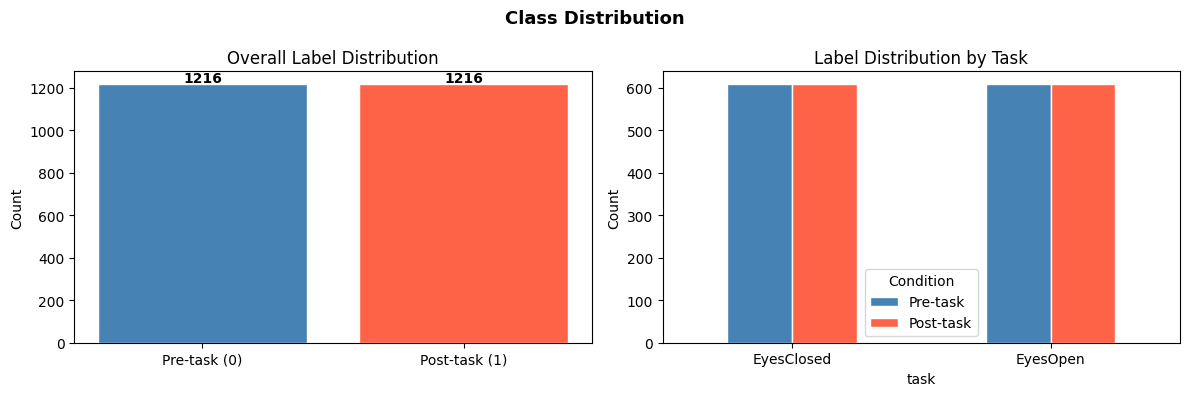

Done


In [2]:
# Cell 2: Class distribution — แยกตาม task
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot 1: Overall label distribution
label_counts = df_all['label'].value_counts()
axes[0].bar(['Pre-task (0)', 'Post-task (1)'],
            label_counts.values,
            color=['steelblue', 'tomato'], edgecolor='white')
for i, val in enumerate(label_counts.values):
    axes[0].text(i, val + 10, str(val), ha='center', fontweight='bold')
axes[0].set_title('Overall Label Distribution')
axes[0].set_ylabel('Count')

# Plot 2: Label distribution per task
task_label = df_all.groupby(['task', 'label']).size().unstack()
task_label.columns = ['Pre-task', 'Post-task']
task_label.plot(kind='bar', ax=axes[1],
                color=['steelblue', 'tomato'],
                edgecolor='white', rot=0)
axes[1].set_title('Label Distribution by Task')
axes[1].set_ylabel('Count')
axes[1].legend(title='Condition')

plt.suptitle('Class Distribution', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/03_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print("Done")

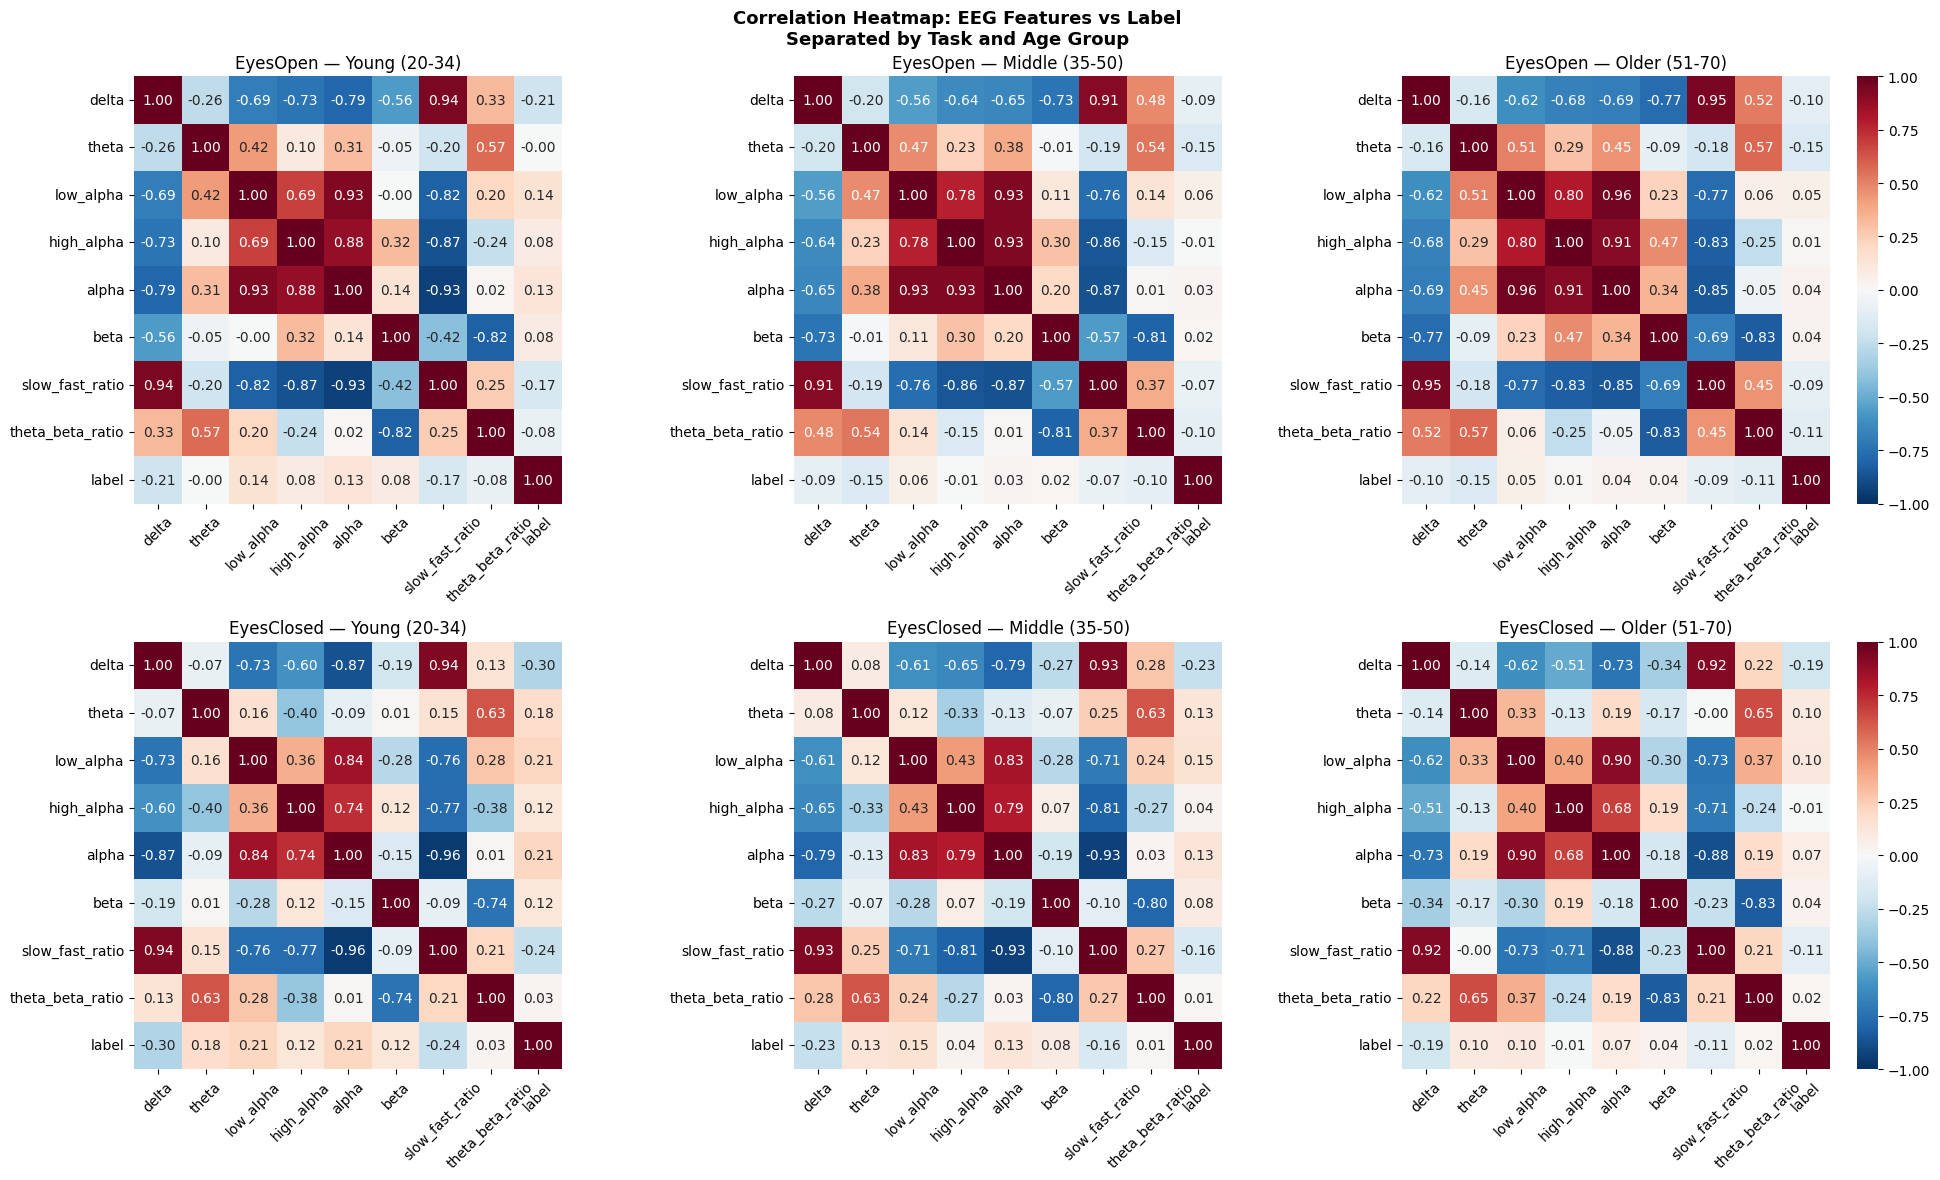

Done


In [3]:
# Cell 3: Correlation heatmap — แยกตาม task
feature_cols = ['delta', 'theta', 'low_alpha', 'high_alpha',
                'alpha', 'beta', 'slow_fast_ratio', 'theta_beta_ratio', 'label']

tasks = ['EyesOpen', 'EyesClosed']

fig, axes = plt.subplots(2, 3, figsize=(20, 12))

age_groups = ['Young (20-34)', 'Middle (35-50)', 'Older (51-70)']

for row, task in enumerate(tasks):
    for col, group in enumerate(age_groups):
        df_sub = df_all[
            (df_all['task'] == task) & 
            (df_all['age_group'] == group)
        ][feature_cols]
        
        corr = df_sub.corr(method='spearman')
        
        sns.heatmap(
            corr,
            ax=axes[row][col],
            annot=True,
            fmt='.2f',
            cmap='RdBu_r',
            center=0,
            vmin=-1, vmax=1,
            square=True,
            cbar=col == 2
        )
        axes[row][col].set_title(f'{task} — {group}')
        axes[row][col].tick_params(axis='x', rotation=45)

plt.suptitle('Correlation Heatmap: EEG Features vs Label\nSeparated by Task and Age Group',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/03_correlation_heatmap_by_task.png', dpi=150, bbox_inches='tight')
plt.show()
print("Done")

In [4]:
# Cell 5: Wilcoxon + FDR + rank-biserial effect size
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
import numpy as np

def rank_biserial(diff):
    """Effect size for Wilcoxon signed-rank test, range -1 to +1"""
    d = diff[diff != 0]
    if len(d) == 0:
        return 0
    from scipy.stats import rankdata
    r = rankdata(np.abs(d))
    return (r[d > 0].sum() - r[d < 0].sum()) / r.sum()

stat_results = []

for task in ['EyesOpen', 'EyesClosed']:
    df_task = df_all[df_all['task'] == task]
    feature_cols_analysis = ['delta', 'theta', 'low_alpha', 'high_alpha', 
                          'alpha', 'beta', 'slow_fast_ratio', 'theta_beta_ratio']
    for feature in feature_cols_analysis:
        pivot = df_task.pivot_table(
            index='subject',
            columns='condition',
            values=feature
        ).dropna()
        
        age_info = df_all[['subject', 'age_group']].drop_duplicates()
        pivot = pivot.merge(age_info, left_index=True, right_on='subject')
        
        for group in ['Young (20-34)', 'Middle (35-50)', 'Older (51-70)']:
            group_data = pivot[pivot['age_group'] == group]
            pre_vals  = group_data['pre'].values
            post_vals = group_data['post'].values
            diff      = post_vals - pre_vals
            
            if len(diff) < 10 or np.all(diff == 0):
                pval = 1.0
                effect_r = 0.0
            else:
                _, pval = wilcoxon(post_vals, pre_vals)
                effect_r = rank_biserial(diff)
            
            stat_results.append({
                'task': task,
                'age_group': group,
                'feature': feature,
                'n': len(diff),
                'median_diff': np.median(diff),
                'pct_increased': (diff > 0).mean() * 100,
                'p_value': pval,
                'effect_r': effect_r
            })

df_stats = pd.DataFrame(stat_results)

# FDR correction: Wilcoxon — applied per task (24 tests per task = 8 features × 3 groups)
# Kruskal — applied across all 16 tests (8 features × 2 tasks)
# Note: these use different denominators by design; both approaches are documented here
for task in ['EyesOpen', 'EyesClosed']:
    mask = df_stats['task'] == task
    pvals = df_stats.loc[mask, 'p_value'].values
    _, pvals_corrected, _, _ = multipletests(pvals, method='fdr_bh')
    df_stats.loc[mask, 'p_fdr'] = pvals_corrected

df_stats['significant'] = df_stats['p_fdr'] < 0.05

print("=== Wilcoxon Results with Effect Size (rank-biserial r) ===")
for task in ['EyesOpen', 'EyesClosed']:
    df_t = df_stats[df_stats['task'] == task]
    sig  = df_t[df_t['significant']]
    print(f"\n--- {task} ({len(sig)}/{len(df_t)} significant) ---")
    print(sig[['age_group', 'feature', 'median_diff', 
               'effect_r', 'p_fdr']].sort_values('effect_r', 
               key=abs, ascending=False).to_string(index=False))

=== Wilcoxon Results with Effect Size (rank-biserial r) ===

--- EyesOpen (13/24 significant) ---
     age_group          feature  median_diff  effect_r        p_fdr
 Young (20-34)        low_alpha     0.243495  0.555491 1.622842e-10
 Young (20-34)            delta    -0.616641 -0.454747 1.635533e-07
 Older (51-70)            theta    -0.093378 -0.426539 1.635533e-07
 Young (20-34)            alpha     0.173867  0.425963 8.531194e-07
 Young (20-34)  slow_fast_ratio    -0.556299 -0.409929 1.967386e-06
Middle (35-50)            theta    -0.095503 -0.317013 1.103285e-03
 Older (51-70) theta_beta_ratio    -0.194994 -0.266704 1.555709e-03
Middle (35-50)        low_alpha     0.050401  0.244805 1.326914e-02
 Older (51-70)            delta    -0.197544 -0.220478 1.123489e-02
 Young (20-34)       high_alpha     0.061244  0.203419 2.611361e-02
 Older (51-70)        low_alpha     0.046954  0.200376 2.021783e-02
Middle (35-50)            delta    -0.386273 -0.195844 4.706568e-02
 Young (20-34)    

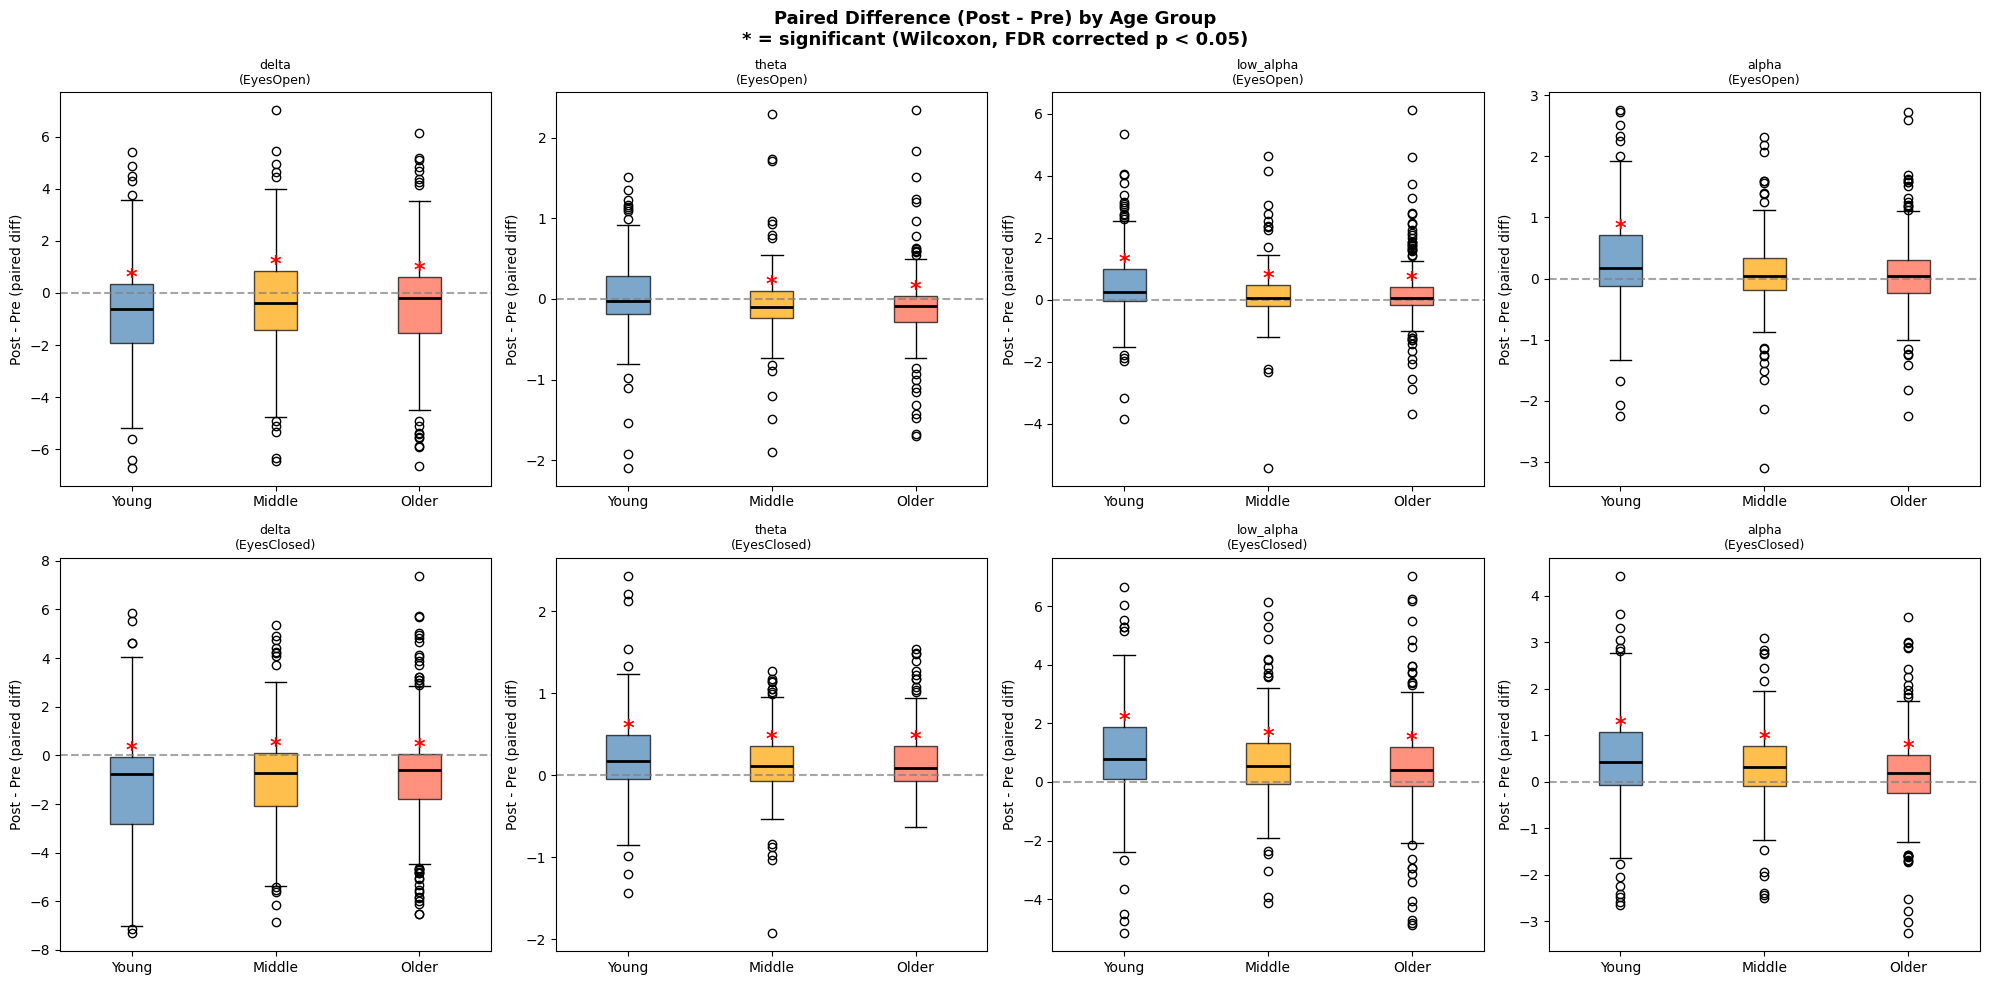

Done


In [5]:
# Cell 6: Visualize paired differences with significance markers
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

features_to_plot = ['delta', 'theta', 'low_alpha', 'alpha']
tasks = ['EyesOpen', 'EyesClosed']
age_groups = ['Young (20-34)', 'Middle (35-50)', 'Older (51-70)']
colors = ['steelblue', 'orange', 'tomato']

for row, task in enumerate(tasks):
    for col, feature in enumerate(features_to_plot):
        ax = axes[row][col]
        
        # get paired diff per age group
        group_diffs = []
        group_labels = []
        
        for group in age_groups:
            df_task = df_all[df_all['task'] == task]
            pivot = df_task.pivot_table(
                index='subject', columns='condition', values=feature
            ).dropna()
            age_info = df_all[['subject', 'age_group']].drop_duplicates()
            pivot = pivot.merge(age_info, left_index=True, right_on='subject')
            diff = pivot[pivot['age_group'] == group]['post'].values - \
                   pivot[pivot['age_group'] == group]['pre'].values
            group_diffs.append(diff)
            group_labels.append(group.split()[0])  # Young/Middle/Older
        
        bp = ax.boxplot(group_diffs, tick_labels=group_labels,
                       patch_artist=True, medianprops=dict(color='black', linewidth=2))
        for patch, color in zip(bp['boxes'], colors):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)
        
        ax.axhline(y=0, color='gray', linestyle='--', alpha=0.7)
        
        # add significance markers
        for i, group in enumerate(age_groups):
            sig_row = df_stats[
                (df_stats['task'] == task) & 
                (df_stats['age_group'] == group) & 
                (df_stats['feature'] == feature)
            ]
            if len(sig_row) > 0 and sig_row['significant'].values[0]:
                ymax = np.percentile(group_diffs[i], 75)
                ax.text(i+1, ymax, '*', ha='center', 
                       fontsize=16, color='red', fontweight='bold')
        
        ax.set_title(f'{feature}\n({task})', fontsize=9)
        ax.set_ylabel('Post - Pre (paired diff)')

plt.suptitle('Paired Difference (Post - Pre) by Age Group\n* = significant (Wilcoxon, FDR corrected p < 0.05)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/03_paired_diff_significance.png', dpi=150, bbox_inches='tight')
plt.show()
print("Done")

In [6]:
# Cell 7: Kruskal-Wallis + log ratio + post-hoc Mann-Whitney
from scipy.stats import kruskal, mannwhitneyu

kruskal_results = []
posthoc_results = []

age_groups_full = ['Young (20-34)', 'Middle (35-50)', 'Older (51-70)']
pairs = [
    ('Young (20-34)', 'Middle (35-50)'),
    ('Young (20-34)', 'Older (51-70)'),
    ('Middle (35-50)', 'Older (51-70)')
]

for task in ['EyesOpen', 'EyesClosed']:
    df_task = df_all[df_all['task'] == task]
    
    for feature in feature_cols_analysis:
        pivot = df_task.pivot_table(
            index='subject', columns='condition', values=feature
        ).dropna()
        age_info = df_all[['subject', 'age_group']].drop_duplicates()
        pivot = pivot.merge(age_info, left_index=True, right_on='subject')
        
        # log ratio แทน raw diff
        pivot['log_ratio'] = np.log(
            pivot['post'].clip(lower=1e-10) / pivot['pre'].clip(lower=1e-10)
        )
        
        group_log = {
            g: pivot[pivot['age_group'] == g]['log_ratio'].values
            for g in age_groups_full
        }
        
        # Kruskal-Wallis
        stat, pval = kruskal(*group_log.values())
        kruskal_results.append({
            'task': task, 'feature': feature,
            'H_statistic': stat, 'p_value': pval
        })
        
        # Post-hoc Mann-Whitney สำหรับทุก feature
        for g1, g2 in pairs:
            _, p_mw = mannwhitneyu(
                group_log[g1], group_log[g2], alternative='two-sided'
            )
            posthoc_results.append({
                'task': task, 'feature': feature,
                'group1': g1, 'group2': g2, 'p_value': p_mw
            })

df_kruskal = pd.DataFrame(kruskal_results)
df_posthoc = pd.DataFrame(posthoc_results)

# FDR correction รวมกัน (consistent)
_, df_kruskal['p_fdr'], _, _ = multipletests(
    df_kruskal['p_value'], method='fdr_bh'
)
df_kruskal['significant'] = df_kruskal['p_fdr'] < 0.05

_, df_posthoc['p_fdr'], _, _ = multipletests(
    df_posthoc['p_value'], method='fdr_bh'
)
df_posthoc['significant'] = df_posthoc['p_fdr'] < 0.05

print("=== Kruskal-Wallis (log ratio) — Age Group Differences ===")
for task in ['EyesOpen', 'EyesClosed']:
    df_k = df_kruskal[df_kruskal['task'] == task]
    sig  = df_k[df_k['significant']]
    print(f"\n--- {task} ({len(sig)}/{len(df_k)} significant) ---")
    print(df_k[['feature', 'H_statistic', 'p_fdr', 
                'significant']].to_string(index=False))

print("\n=== Post-hoc Mann-Whitney (significant Kruskal features only) ===")
sig_features = df_kruskal[df_kruskal['significant']][['task', 'feature']]
for _, row in sig_features.iterrows():
    ph = df_posthoc[
        (df_posthoc['task'] == row['task']) & 
        (df_posthoc['feature'] == row['feature'])
    ]
    print(f"\n{row['task']} — {row['feature']}")
    print(ph[['group1', 'group2', 'p_fdr', 'significant']].to_string(index=False))

=== Kruskal-Wallis (log ratio) — Age Group Differences ===

--- EyesOpen (3/8 significant) ---
         feature  H_statistic    p_fdr  significant
           delta     5.904019 0.091841        False
           theta    17.561669 0.002458         True
       low_alpha    15.982974 0.002707         True
      high_alpha     5.715393 0.091841        False
           alpha    10.540087 0.021075         True
            beta     2.412077 0.342150        False
 slow_fast_ratio     6.919700 0.071850        False
theta_beta_ratio     0.913423 0.675587        False

--- EyesClosed (3/8 significant) ---
         feature  H_statistic    p_fdr  significant
           delta     2.835434 0.298174        False
           theta     4.817688 0.130792        False
       low_alpha     8.949882 0.030376         True
      high_alpha    10.491952 0.021075         True
           alpha     8.958070 0.030376         True
            beta     3.148764 0.276181        False
 slow_fast_ratio     5.980839 0.091

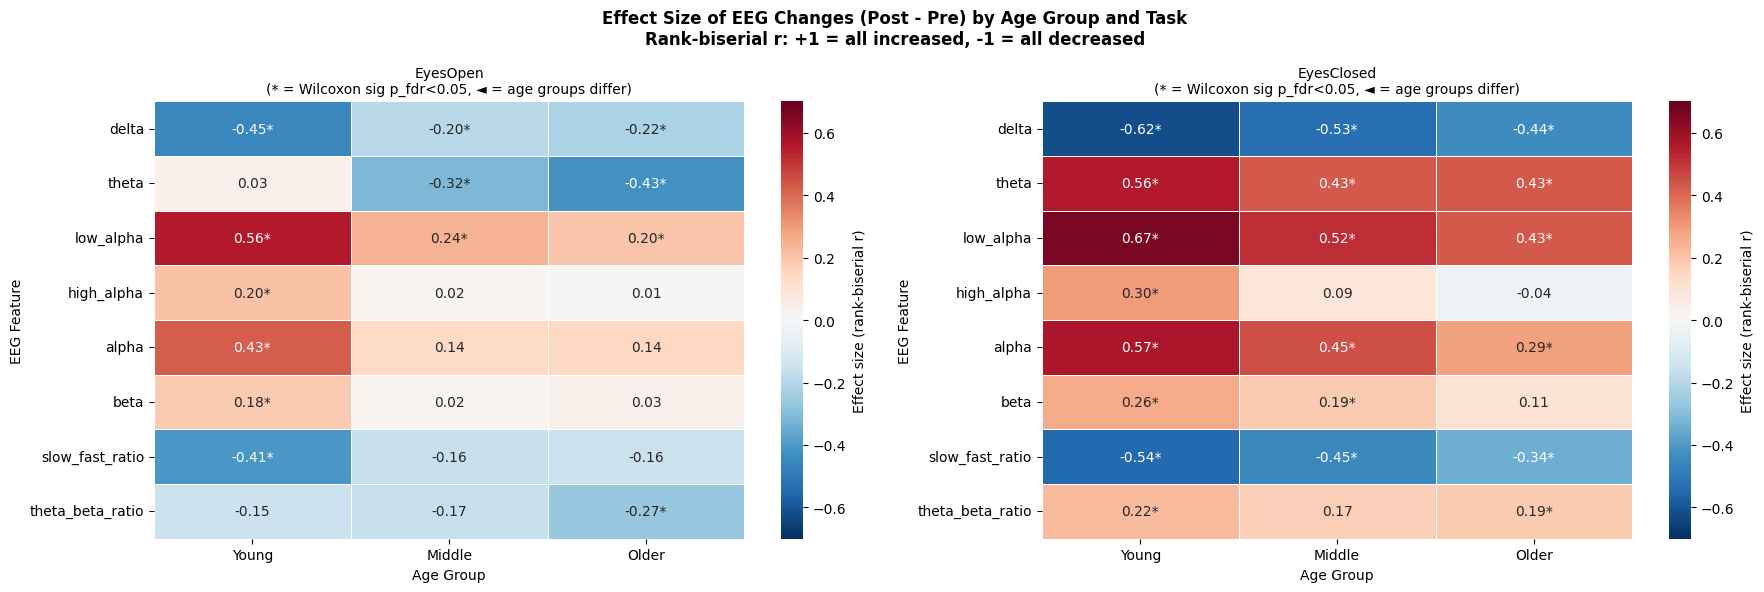

Done


In [7]:
# Cell 8: Heatmap ด้วย effect size (rank-biserial r)
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

tasks = ['EyesOpen', 'EyesClosed']
age_groups_short = ['Young', 'Middle', 'Older']
age_groups_full  = ['Young (20-34)', 'Middle (35-50)', 'Older (51-70)']
features_plot = ['delta', 'theta', 'low_alpha', 'high_alpha',
                 'alpha', 'beta', 'slow_fast_ratio', 'theta_beta_ratio']

for col, task in enumerate(tasks):
    matrix = []
    annot  = []
    
    for feature in features_plot:
        row_vals  = []
        row_annot = []
        
        for group_full, group_short in zip(age_groups_full, age_groups_short):
            # get effect size
            stat_row = df_stats[
                (df_stats['task'] == task) &
                (df_stats['age_group'] == group_full) &
                (df_stats['feature'] == feature)
            ]
            
            if len(stat_row) == 0:
                r = 0
                sig = False
            else:
                r   = stat_row['effect_r'].values[0]
                sig = stat_row['significant'].values[0]
            
            row_vals.append(r)
            row_annot.append(f"{r:.2f}{'*' if sig else ''}")
        
        matrix.append(row_vals)
        annot.append(row_annot)
    
    df_matrix = pd.DataFrame(matrix,
                             index=features_plot,
                             columns=age_groups_short)
    
    sns.heatmap(
        df_matrix,
        ax=axes[col],
        annot=annot,
        fmt='',
        cmap='RdBu_r',
        center=0,
        vmin=-0.7, vmax=0.7,
        linewidths=0.5,
        cbar_kws={'label': 'Effect size (rank-biserial r)'}
    )
    
    # Mark Kruskal significant features
    df_k_task = df_kruskal[df_kruskal['task'] == task]
    for i, feature in enumerate(features_plot):
        k_row = df_k_task[df_k_task['feature'] == feature]
        if len(k_row) > 0 and k_row['significant'].values[0]:
            axes[col].annotate('◄', xy=(3.05, i + 0.5),
                              xycoords='data', fontsize=10,
                              color='purple', va='center')
    
    axes[col].set_title(
        f'{task}\n(* = Wilcoxon sig p_fdr<0.05, ◄ = age groups differ)',
        fontsize=10
    )
    axes[col].set_xlabel('Age Group')
    axes[col].set_ylabel('EEG Feature')

plt.suptitle('Effect Size of EEG Changes (Post - Pre) by Age Group and Task\n'
             'Rank-biserial r: +1 = all increased, -1 = all decreased',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/03_effect_size_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("Done")

In [8]:
# Cell สุดท้าย: Sensitivity analysis และ high alpha baseline comparison

# 1. Sensitivity analysis — ตัด late_ses1 > 0 ออก
p_late = pd.read_csv('Dataset/participants.tsv', sep='\t')[['participant_id', 'late_ses1']]
df_sens = df_all.merge(p_late, left_on='subject', right_on='participant_id').drop(columns='participant_id')

df_clean = df_sens[df_sens['late_ses1'] == 0]
print(f"Full dataset:    {df_all['subject'].nunique()} subjects")
print(f"After exclusion: {df_clean['subject'].nunique()} subjects")

# เทียบผล low_alpha EyesClosed หลังตัด
for label, df_use in [('Full', df_sens), ('Excluded late_ses1>0', df_clean)]:
    df_ec = df_use[df_use['task'] == 'EyesClosed']
    pivot = df_ec.pivot_table(index='subject', columns='condition', values='low_alpha').dropna()
    age_info = df_use[['subject', 'age_group']].drop_duplicates()
    pivot = pivot.merge(age_info, left_index=True, right_on='subject')
    
    print(f"\n--- {label} ---")
    for group in ['Young (20-34)', 'Middle (35-50)', 'Older (51-70)']:
        g = pivot[pivot['age_group'] == group]
        diff = g['post'].values - g['pre'].values
        from scipy.stats import wilcoxon
        _, pval = wilcoxon(g['post'], g['pre'])
        print(f"  {group}: median diff={np.median(diff):.3f}, p={pval:.4f}")

# 2. High alpha baseline comparison (replicating Yang et al.)
print("\n=== High Alpha at Baseline (Pre-task, EyesClosed) across Age Groups ===")
pre_ec = df_all[(df_all['condition'] == 'pre') & (df_all['task'] == 'EyesClosed')]
age_groups_full = ['Young (20-34)', 'Middle (35-50)', 'Older (51-70)']

vals = [pre_ec[pre_ec['age_group'] == g]['high_alpha'].values for g in age_groups_full]
for group, v in zip(age_groups_full, vals):
    print(f"  {group}: median={np.median(v):.4f} (n={len(v)})")

from scipy.stats import kruskal
stat, pval = kruskal(*vals)
print(f"\nKruskal-Wallis: H={stat:.3f}, p={pval:.2e}")
if pval < 0.05:
    print("-> Age groups differ in baseline high alpha (consistent with Yang et al.)")
else:
    print("-> Age groups do NOT differ significantly in baseline high alpha")

Full dataset:    608 subjects
After exclusion: 517 subjects

--- Full ---
  Young (20-34): median diff=0.767, p=0.0000
  Middle (35-50): median diff=0.538, p=0.0000
  Older (51-70): median diff=0.400, p=0.0000

--- Excluded late_ses1>0 ---
  Young (20-34): median diff=0.675, p=0.0000
  Middle (35-50): median diff=0.538, p=0.0000
  Older (51-70): median diff=0.400, p=0.0000

=== High Alpha at Baseline (Pre-task, EyesClosed) across Age Groups ===
  Young (20-34): median=1.9203 (n=203)
  Middle (35-50): median=1.8337 (n=175)
  Older (51-70): median=1.4550 (n=230)

Kruskal-Wallis: H=15.368, p=4.60e-04
-> Age groups differ in baseline high alpha (consistent with Yang et al.)


In [9]:
# ── Continuous age: Spearman rho of log_ratio vs age ──────────────────────
from scipy.stats import spearmanr
feats = ['delta', 'theta', 'low_alpha', 'high_alpha', 
         'alpha', 'beta', 'slow_fast_ratio', 'theta_beta_ratio']
print("=== Spearman rho: log(post/pre) vs age ===")
print(f"{'Task':<12} {'Feature':<12} {'rho':>7} {'p':>10}")
print("-" * 44)
for task in ['EyesOpen', 'EyesClosed']:
    d = df_all[df_all['task'] == task]
    piv = d.pivot_table(index='subject', columns='condition', values=feats)
    age_map = d.drop_duplicates('subject').set_index('subject')['age']
    for f in ['low_alpha', 'high_alpha', 'alpha', 'theta']:
        try:
            pre  = piv[(f, 'pre')]
            post = piv[(f, 'post')]
            idx  = pre.dropna().index.intersection(post.dropna().index)
            logr = np.log(post.loc[idx] / pre.loc[idx])
            age  = age_map.loc[logr.index]
            rho, pv = spearmanr(age, logr)
            sig = "✅" if pv < 0.05 else ""
            print(f"{task:<12} {f:<12} {rho:>+7.3f} {pv:>10.2e} {sig}")
        except Exception as e:
            print(f"{task:<12} {f:<12} ERROR: {e}")
    print()

=== Spearman rho: log(post/pre) vs age ===
Task         Feature          rho          p
--------------------------------------------
EyesOpen     low_alpha     -0.149   2.26e-04 ✅
EyesOpen     high_alpha    -0.100   1.40e-02 ✅
EyesOpen     alpha         -0.124   2.26e-03 ✅
EyesOpen     theta         -0.162   6.27e-05 ✅

EyesClosed   low_alpha     -0.111   6.16e-03 ✅
EyesClosed   high_alpha    -0.116   4.34e-03 ✅
EyesClosed   alpha         -0.102   1.16e-02 ✅
EyesClosed   theta         -0.100   1.37e-02 ✅



In [10]:
# ── Sex × age_group chi-square ─────────────────────────────────────────────
from scipy.stats import chi2_contingency

subj = df_all.drop_duplicates('subject')[['subject', 'age_group', 'sex']]
ct = pd.crosstab(subj['age_group'], subj['sex'])
ct = ct.reindex(['Young (20-34)', 'Middle (35-50)', 'Older (51-70)'])
print("=== Sex distribution by age group ===")
print(ct)
chi2, p, dof, expected = chi2_contingency(ct)
print(f"\nChi-square = {chi2:.3f}, df = {dof}, p = {p:.3e}")
if p < 0.05:
    print("⚠️  Sex distribution differs across age groups — potential confound")
    print("    Consider including sex as covariate or reporting separately")
else:
    print("✅  Sex distribution balanced across age groups")

=== Sex distribution by age group ===
sex               F   M
age_group              
Young (20-34)   134  69
Middle (35-50)  109  66
Older (51-70)   133  97

Chi-square = 3.081, df = 2, p = 2.143e-01
✅  Sex distribution balanced across age groups


### Continuous Age Analysis (Spearman)

Spearman correlation between log(post/pre) and age (years) was negative and
significant for all alpha-band features in both tasks (rho = −0.10 to −0.16,
p < 0.05 FDR-uncorrected), confirming that the age-group difference is not
an artifact of arbitrary binning: older participants show smaller fatigue-related
alpha increases across the age range.

"Age correlated weakly but consistently with log(post/pre) for alpha-band features (ρ = −0.10 to −0.16, all FDR < 0.05). Post-hoc results (Young ≠ Older; Middle ≈ Older) suggest the effect is concentrated in the youngest group."

Theta log ratio also correlates negatively with age (EO: rho=−0.162, p<0.001),
consistent with the Kruskal-Wallis post-hoc result.

### Sex as Confound

Chi-square test shows sex distribution is balanced across age groups
(χ²=3.08, df=2, p=0.21). Sex was not included as a covariate.

## EDA Summary & Comparison with Yang et al. (2025)

### Key Findings

**1. EyesClosed condition shows stronger and more consistent effects**
- 20/24 Wilcoxon tests significant vs 13/24 for EyesOpen
- Separating eyes conditions is critical — mixing them would obscure results
- Note: EC was always recorded before EO in this dataset, so we cannot 
  rule out ordering effects (EC effect may partly reflect earlier post-task timing)

**2. Low alpha shows the most consistent change after cognitive task**
- Relative low-alpha increased post-task in ALL age groups, BOTH conditions
- EyesClosed effect sizes: Young r=0.67, Middle r=0.52, Older r=0.43
- However: Yang et al. reported DECREASED aperiodic-corrected low-alpha in young adults
- This discrepancy may relate to methodological differences: Yang et al. applied
FOOOF to remove the aperiodic (1/f) component before computing band power,
whereas we use relative power. The mechanism is unclear and would require
specparam analysis to verify.
- Future work: apply FOOOF/specparam to separate periodic from aperiodic components

**3. Young group shows the largest EEG changes**
Young shows the largest alpha-band changes (EyesOpen: robust to sensitivity
analysis; EyesClosed: significant in full dataset, attenuated after excluding
late-trigger subjects — treat as exploratory).

**4. Theta reverses direction depending on eyes condition**
- EyesOpen: theta decreases in Middle/Older (r≈-0.32 to -0.43*), 
  Young shows negligible non-significant change
- EyesClosed: theta increases in ALL groups (r=0.43–0.56*)
- Completely invisible if conditions were mixed — confirms importance of separation

**5. slow_fast_ratio reflects combined changes in delta AND alpha**
- Decreases because BOTH delta drops AND alpha increases post-task
- Originally from drowsy driving literature — interpret with caution
- Not validated as a cognitive fatigue biomarker in resting-state EEG

**6. theta_beta_ratio shows minimal age group differences**
- Kruskal-Wallis p ≈ 0.68–0.96 — not significant in either condition
- Reverses direction by eyes condition (same as theta)
- Does not support strong claims about age-related differences

### Comparison with Yang et al. (2025)

| Finding | Yang et al. | This study |
|---|---|---|
| Young more sensitive to fatigue | ✅ Statistical (low-alpha power & network efficiency) | ✅ Post-hoc Mann-Whitney |
| Low alpha changes with fatigue | ✅ Decreases (aperiodic-corrected) | ⚠️ Increases (relative power) |
| High alpha | Reflects aging (between-group), not fatigue | Baseline differs by age (H=15.37, p<0.001) ✅; post-task change in Young only (EC), not robust to sensitivity analysis |
| EyesClosed stronger effects | Reported EC results primarily | ✅ Observed (more significant tests in full dataset; attenuated after sensitivity analysis — treat as exploratory) |

*Yang et al. compared high alpha BETWEEN age groups at baseline (aging effect).
We tested high alpha change PRE→POST within each group (fatigue effect).
These are different comparisons. To replicate Yang's finding properly:

```python
pre = df_all[(df_all['condition'] == 'pre') & (df_all['task'] == 'EyesClosed')]
# Run Kruskal-Wallis on pre-task high_alpha across age groups
```

### Limitations & Future Work
- Relative power does not separate periodic from aperiodic EEG components
  (FOOOF/specparam needed to fully replicate Yang et al.)
- EC recorded before EO — ordering effect cannot be ruled out
- Sensitivity analysis (excluding 91 subjects with late_ses1 > 0) confirms
EyesOpen findings are robust. EyesClosed between-group differences are
attenuated after exclusion and should be treated as exploratory.

In [11]:
from scipy.stats import wilcoxon, kruskal, mannwhitneyu, rankdata
from statsmodels.stats.multitest import multipletests
pairs_ph = [('Young (20-34)', 'Middle (35-50)'),
            ('Young (20-34)', 'Older (51-70)'),
            ('Middle (35-50)', 'Older (51-70)')]
def rank_biserial(diff):
    d = diff[diff != 0]
    if len(d) == 0:
        return 0.0
    r = rankdata(np.abs(d))
    return (r[d > 0].sum() - r[d < 0].sum()) / r.sum()

def run_all(df):
    res_w, diffs_store, logr_store = [], {}, {}

    # ── Wilcoxon (diff) + เก็บ log ratio ──────────────────────────────────
    for (task, g), d in df.groupby(['task', 'age_group']):
        piv = d.pivot_table(index='subject', columns='condition', values=feats)
        for f in feats:
            try:
                pre  = piv[(f, 'pre')].dropna()
                post = piv[(f, 'post')].dropna()
                idx  = pre.index.intersection(post.index)
                pre, post = pre.loc[idx], post.loc[idx]
                diff = post - pre
                logr = np.log(post / pre)          # log ratio (post/pre > 0 เสมอ)
                diffs_store[(task, f, g)] = diff
                logr_store[(task, f, g)]  = logr   # ใช้กับ Kruskal/post-hoc
                _, pval = wilcoxon(post, pre)
                res_w.append({'task': task, 'age_group': g, 'feature': f,
                              'n': len(idx),
                              'median_diff': diff.median(),
                              'effect_r': rank_biserial(diff),
                              'pct_increased': (diff > 0).mean() * 100,
                              'p_wilcoxon': pval})
            except Exception as e:
                print(f"  [WARN] Wilcoxon {task} {g} {f}: {e}")
                res_w.append({'task': task, 'age_group': g, 'feature': f,
                              'n': 0, 'median_diff': np.nan,
                              'effect_r': np.nan, 'pct_increased': np.nan,
                              'p_wilcoxon': np.nan})

    df_stats = pd.DataFrame(res_w)
    for task in df_stats['task'].unique():
        mask = df_stats['task'] == task
        _, pfc, _, _ = multipletests(df_stats.loc[mask, 'p_wilcoxon'].fillna(1), method='fdr_bh')
        df_stats.loc[mask, 'p_fdr'] = pfc
    df_stats['sig'] = df_stats['p_fdr'] < 0.05

    # ── Kruskal-Wallis บน log ratio ────────────────────────────────────────
    res_k = []
    for task in df['task'].unique():
        for f in feats:
            groups = [logr_store.get((task, f, g), pd.Series(dtype=float))
                      for g in age_groups_full]
            groups = [g for g in groups if len(g) > 0]
            if len(groups) < 2:
                continue
            try:
                H, pval = kruskal(*groups)
            except Exception as e:
                print(f"  [WARN] Kruskal {task} {f}: {e}")
                H, pval = np.nan, np.nan
            res_k.append({'task': task, 'feature': f, 'H': H, 'p_kruskal': pval})

    df_kruskal = pd.DataFrame(res_k)
    _, pfc, _, _ = multipletests(df_kruskal['p_kruskal'].fillna(1), method='fdr_bh')
    df_kruskal['p_fdr'] = pfc
    df_kruskal['sig'] = df_kruskal['p_fdr'] < 0.05

    # ── Post-hoc Mann-Whitney บน log ratio ────────────────────────────────
    res_ph = []
    for _, row in df_kruskal[df_kruskal['sig']].iterrows():
        task, f = row['task'], row['feature']
        for g1, g2 in pairs_ph:
            d1 = logr_store.get((task, f, g1), pd.Series(dtype=float))
            d2 = logr_store.get((task, f, g2), pd.Series(dtype=float))
            if len(d1) == 0 or len(d2) == 0:
                continue
            stat, pval = mannwhitneyu(d1, d2, alternative='two-sided')
            # ทิศทาง: median log ratio ของแต่ละกลุ่ม
            med1 = d1.median(); med2 = d2.median()
            res_ph.append({'task': task, 'feature': f,
                           'pair': f'{g1} vs {g2}',
                           f'median_logr_{g1[:5]}': med1,
                           f'median_logr_{g2[:5]}': med2,
                           'p_mw': pval})

    df_posthoc = pd.DataFrame(res_ph) if res_ph else pd.DataFrame(
        columns=['task', 'feature', 'pair', 'p_mw'])
    if len(df_posthoc):
        _, pfc, _, _ = multipletests(df_posthoc['p_mw'], method='fdr_bh')
        df_posthoc['p_fdr'] = pfc
        df_posthoc['sig'] = df_posthoc['p_fdr'] < 0.05

    return df_stats, df_kruskal, df_posthoc


# ── safe merge late_ses1 (ไม่พังถ้ารันซ้ำ) ────────────────────────────────
p_late = pd.read_csv('Dataset/participants.tsv', sep='\t')[['participant_id', 'late_ses1']]
df_all = df_all.drop(columns='late_ses1', errors='ignore')
df_all = df_all.merge(p_late, left_on='subject', right_on='participant_id',
                      how='left').drop(columns='participant_id')
df_all['late_ses1'] = df_all['late_ses1'].fillna(0)
df_clean = df_all[df_all['late_ses1'] == 0].copy()

# ── n per age group ────────────────────────────────────────────────────────
subj_late = df_all.drop_duplicates('subject')[['subject', 'age_group', 'late_ses1']]
print("=== Subjects per age group ===")
print(f"{'Group':<22} {'Total':>6} {'late>0':>8} {'Kept':>6}")
print("-" * 44)
for g in age_groups_full:
    tot  = (subj_late['age_group'] == g).sum()
    excl = ((subj_late['age_group'] == g) & (subj_late['late_ses1'] > 0)).sum()
    print(f"{g:<22} {tot:>6} {excl:>8} {tot-excl:>6}")

# ── รัน ────────────────────────────────────────────────────────────────────
print("\n⏳ Full (n=608)...")
stats_full, krus_full, ph_full = run_all(df_all)
print("⏳ Clean (late_ses1=0)...")
stats_clean, krus_clean, ph_clean = run_all(df_clean)

# ── เปรียบ Kruskal ทุก feature (ตารางเต็ม) ────────────────────────────────
print("\n=== Kruskal p_fdr: Full vs Clean (log ratio) ===")
cmp = krus_full.merge(krus_clean, on=['task','feature'], suffixes=('_full','_clean'))
print(cmp[['task','feature','H_full','p_fdr_full','H_clean','p_fdr_clean']].round(4).to_string(index=False))

# ── low_alpha EC เปรียบ ────────────────────────────────────────────────────
print("\n=== low_alpha | EyesClosed — effect_r (Wilcoxon) ===")
for g in age_groups_full:
    rf = stats_full[(stats_full['task']=='EyesClosed') &
                    (stats_full['feature']=='low_alpha') &
                    (stats_full['age_group']==g)].iloc[0]
    rc = stats_clean[(stats_clean['task']=='EyesClosed') &
                     (stats_clean['feature']=='low_alpha') &
                     (stats_clean['age_group']==g)].iloc[0]
    print(f"{g:<22}  Full r={rf['effect_r']:+.3f}  Clean r={rc['effect_r']:+.3f}")

# ── post-hoc ───────────────────────────────────────────────────────────────
if len(ph_full):
    print("\n=== Post-hoc significant — Full ===")
    print(ph_full[ph_full['sig']].to_string(index=False))
if len(ph_clean):
    print("\n=== Post-hoc significant — Clean ===")
    print(ph_clean[ph_clean['sig']].to_string(index=False))

=== Subjects per age group ===
Group                   Total   late>0   Kept
--------------------------------------------
Young (20-34)             203       31    172
Middle (35-50)            175       22    153
Older (51-70)             230       38    192

⏳ Full (n=608)...
⏳ Clean (late_ses1=0)...

=== Kruskal p_fdr: Full vs Clean (log ratio) ===
      task          feature  H_full  p_fdr_full  H_clean  p_fdr_clean
  EyesOpen            delta  5.9040      0.0918   6.4241       0.1031
  EyesOpen            theta 17.5617      0.0025  14.1270       0.0068
  EyesOpen        low_alpha 15.9830      0.0027  15.0807       0.0068
  EyesOpen       high_alpha  5.7154      0.0918   6.8646       0.1031
  EyesOpen            alpha 10.5401      0.0211  10.6810       0.0256
  EyesOpen             beta  2.4121      0.3421   3.5342       0.2485
  EyesOpen  slow_fast_ratio  6.9197      0.0719   7.7698       0.0822
  EyesOpen theta_beta_ratio  0.9134      0.6756   0.3807       0.8267
EyesClosed      

## Sensitivity Analysis Summary (excluding 91 subjects with late_ses1 > 0)

All tests use log(post/pre). Kruskal-Wallis FDR-corrected across 16 tests;
post-hoc Mann-Whitney run only for Kruskal-significant features.

### A. Kruskal-Wallis (3 age groups)

| Task | Feature | Full (n=608) | Clean (n=517) | Robust? |
|---|---|---|---|---|
| EO | theta | p_fdr=0.003 | p_fdr=0.007 | ✅ Yes |
| EO | low_alpha | p_fdr=0.003 | p_fdr=0.007 | ✅ Yes |
| EO | alpha | p_fdr=0.021 | p_fdr=0.026 | ✅ Yes |
| EC | low_alpha | p_fdr=0.030 | p_fdr=0.197 | ❌ No |
| EC | high_alpha | p_fdr=0.021 | p_fdr=0.103 | ❌ No |
| EC | alpha | p_fdr=0.030 | p_fdr=0.197 | ❌ No |

### B. Post-hoc pairwise (EyesOpen only; EC not tested in clean set because Kruskal n.s.)

| Feature | Pair | Full | Clean | Robust? |
|---|---|---|---|---|
| theta | Young vs Older | p_fdr=0.001 | p_fdr=0.002 | ✅ Yes |
| theta | Young vs Middle | p_fdr=0.008 | p_fdr=0.007 | ✅ Yes |
| low_alpha | Young vs Older | p_fdr=0.001 | p_fdr<0.001 | ✅ Yes |
| low_alpha | Young vs Middle | p_fdr=0.008 | n.s. | ❌ No |
| alpha | Young vs Older | p_fdr=0.008 | p_fdr=0.003 | ✅ Yes |
| alpha | Young vs Middle | p_fdr=0.016 | n.s. | ❌ No |
| all features | Middle vs Older | n.s. | n.s. | — |

Direction (median log ratio, EO, full set): Young shows a larger low-alpha
increase than Older (+0.195 vs +0.030) and a smaller theta decrease
(−0.020 vs −0.084).

### C. Within-group change (Wilcoxon effect size, low_alpha EC)

| Group | Full r | Clean r |
|---|---|---|
| Young | +0.666 | +0.663 |
| Middle | +0.518 | +0.506 |
| Older | +0.429 | +0.474 |

**Interpretation:**
- **Robust:** In EyesOpen, Young differs from Older in theta, low-alpha and
  alpha changes after the task. This holds after excluding late-trigger subjects.
- **Not robust:** Young vs Middle differences in low-alpha and alpha, and all
  EyesClosed between-group differences, do not survive exclusion; treat as exploratory.
- **Stable:** The pre→post increase in EC low-alpha within each age group is
  unchanged by exclusion (effect sizes differ by < 0.05).

In [1]:
# ── age × fatigue interaction บนข้อมูล v4 ──
import numpy as np, pandas as pd
from scipy.stats import mannwhitneyu

VER, ALPHA = 'v4', 0.05
REG  = ['frontal', 'central', 'occipital']
MEAS = ['low_alpha_corr', 'high_alpha_corr', 'low_alpha_rel',
        'high_alpha_rel', 'ap_exponent', 'ap_offset']

df   = pd.read_csv(f'outputs/fooof_features_{VER}.csv')
df   = df[df['ap_exponent'] > 0]
ages = pd.read_csv('Dataset/participants.tsv', sep='\t').set_index('participant_id')['age']

k = ['subject', 'task', 'region']
P = df[df.condition == 'pre' ].set_index(k)
Q = df[df.condition == 'post'].set_index(k)
M = P.join(Q, lsuffix='_pre', rsuffix='_post', how='inner').reset_index()
M['group'] = M['subject'].map(ages).apply(
    lambda a: 'Young' if a <= 34 else ('Older' if a >= 51 else 'Middle'))
EC = M[(M.task == 'EyesClosed') & (M.group != 'Middle')].copy()
for m in MEAS:
    EC[f'd_{m}'] = EC[f'{m}_post'] - EC[f'{m}_pre']

rows = []
for rg, d in EC.groupby('region'):
    for m in MEAS:
        y = d[d.group == 'Young'][f'd_{m}'].dropna()
        o = d[d.group == 'Older'][f'd_{m}'].dropna()
        if len(y) < 10 or len(o) < 10:
            continue
        _, p = mannwhitneyu(y, o, alternative='two-sided')
        rows.append({'region': rg, 'measure': m, 'n_young': len(y), 'n_older': len(o),
                     'median_change_young': y.median(), 'median_change_older': o.median(),
                     'larger_in': 'Young' if abs(y.median()) > abs(o.median()) else 'Older',
                     'p': p})
inter = pd.DataFrame(rows)
inter['p_bonf'] = (inter['p'] * len(inter)).clip(upper=1)
inter['region'] = pd.Categorical(inter['region'], REG, ordered=True)
inter = inter.sort_values(['measure', 'region'])

print("=== Does the fatigue effect differ by age? (EC, change post−pre) ===")
print(inter.round(4).to_string(index=False))
print(f"\nมีนัยสำคัญหลัง Bonferroni: {int((inter['p_bonf'] < ALPHA).sum())}/{len(inter)}")
sig = inter[inter['p_bonf'] < ALPHA]
if len(sig):
    print(sig[['region','measure','median_change_young','median_change_older',
               'larger_in','p_bonf']].round(4).to_string(index=False))

inter.to_csv('outputs/age_fatigue_interaction.csv', index=False)

=== Does the fatigue effect differ by age? (EC, change post−pre) ===
   region         measure  n_young  n_older  median_change_young  median_change_older larger_in      p  p_bonf
  frontal     ap_exponent      203      230              -0.0310              -0.0587     Older 0.4441  1.0000
  central     ap_exponent      203      230              -0.0582              -0.0801     Older 0.0355  0.6387
occipital     ap_exponent      203      229              -0.0129              -0.0465     Older 0.2068  1.0000
  frontal       ap_offset      203      230              -0.0415              -0.0185     Young 0.3524  1.0000
  central       ap_offset      203      230              -0.0289              -0.0390     Older 0.4211  1.0000
occipital       ap_offset      203      229               0.0003               0.0002     Young 0.4661  1.0000
  frontal high_alpha_corr      203      230              -0.0012              -0.0044     Older 0.7047  1.0000
  central high_alpha_corr      203      230